In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import os

os.chdir('/content/drive/MyDrive/Loan')
os.getcwd()

'/content/drive/MyDrive/Loan'

# Loan Eligibility Prediction
## Exploratory Data Analysis (EDA) Report

---

| Detail | Information |
|---|---|
| **Project Title** | Loan Eligibility Prediction using Machine Learning |
| **Domain** | Banking and Finance |
| **Language** | Python 3 |
| **Notebook Purpose** | Comparative Exploratory Data Analysis (EDA) |

---

### Prepared By:
- **Shreedhar Khorate** (Roll Number: 25101B2007)
- **Bhushan Avhad** (Roll Number: 25101B2006)

---

This notebook performs an Exploratory Data Analysis comparing the original dataset (`Loan_Data.csv`) and the cleaned/imputed dataset (`Loan_Data_Cleaned.csv`). We will generate insights about candidate profiles, distributions, missing values, and the impact of the data cleaning pipeline.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='muted')

# Load datasets
df_orig = pd.read_csv('/content/drive/MyDrive/Loan/Loan_Data.csv')
df_clean = pd.read_csv('/content/drive/MyDrive/Loan/Loan_Data_Cleaned.csv')

print(f"Original Dataset: {df_orig.shape[0]} rows, {df_orig.shape[1]} columns")
print(f"Cleaned Dataset : {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")

Original Dataset: 614 rows, 13 columns
Cleaned Dataset : 529 rows, 21 columns


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Dataset Comparison

In [11]:
missing_orig = df_orig.isnull().sum()
missing_clean = df_clean.isnull().sum()

missing_df = pd.DataFrame({
    'Original Nulls': missing_orig,
    'Cleaned Nulls': missing_clean
})
print("Missing Values Comparison:")
print(missing_df[missing_df['Original Nulls'] > 0])

Missing Values Comparison:
                  Original Nulls  Cleaned Nulls
Credit_History              50.0              0
Dependents                  15.0              0
Gender                      13.0              0
LoanAmount                  22.0              0
Loan_Amount_Term            14.0              0
Married                      3.0              0
Self_Employed               32.0              0


### Insight 1: Imputation Clears Missing Data Bias

**Description:**  
The original dataset suffered from significant missing information in key fields like `Credit_History` (8.14% missing), `Self_Employed` (5.21% missing), and `LoanAmount` (3.58% missing). In the cleaned dataset, these missing values have been successfully imputed (modes for categorical, medians for continuous). This guarantees that subsequent modeling avoids dropping incomplete records or introducing bias due to missing indicators.

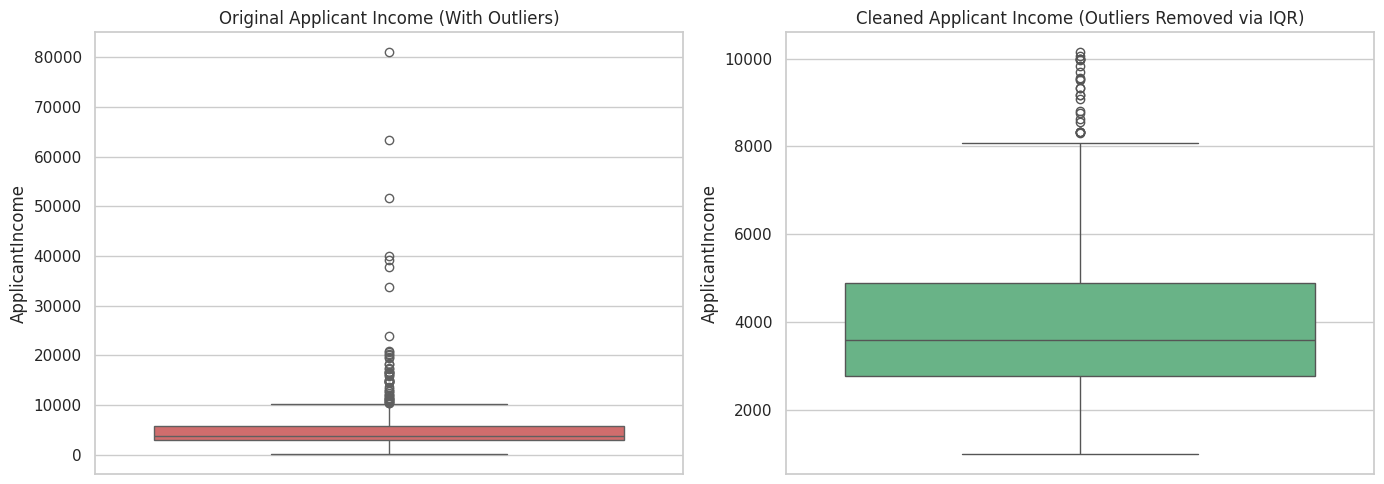

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_orig, y='ApplicantIncome', ax=axes[0], color='#e05c5c')
axes[0].set_title('Original Applicant Income (With Outliers)')

sns.boxplot(data=df_clean, y='ApplicantIncome', ax=axes[1], color='#5dbf85')
axes[1].set_title('Cleaned Applicant Income (Outliers Removed via IQR)')

plt.tight_layout()
plt.show()

### Insight 2: Outlier Filtering Normalizes Distribution Ranges

**Description:**
Applying IQR outlier filtration on `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount` reduces distribution right-skewness and trims extreme values. However, it represents a population filtration trade-off: 80 real applicant records (13.1%) are removed, reducing the maximum income from 81,000 to 10,139 INR/month.


## Univariate Analysis (Distributions & Counts)

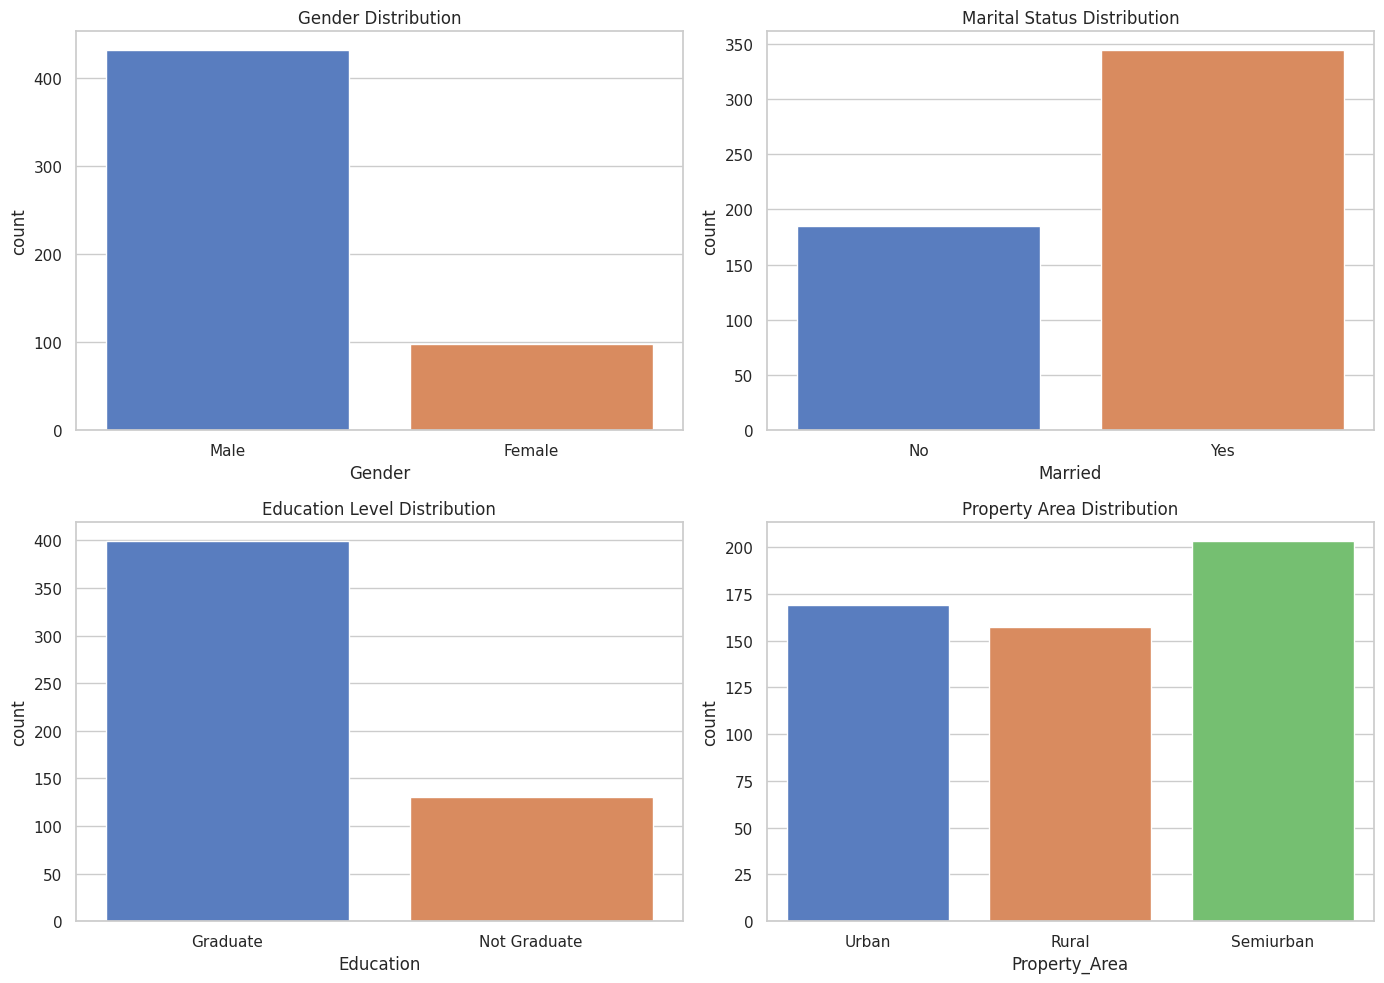

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_clean, x='Gender', ax=axes[0,0], hue='Gender', legend=False)
axes[0,0].set_title('Gender Distribution')

sns.countplot(data=df_clean, x='Married', ax=axes[0,1], hue='Married', legend=False)
axes[0,1].set_title('Marital Status Distribution')

sns.countplot(data=df_clean, x='Education', ax=axes[1,0], hue='Education', legend=False)
axes[1,0].set_title('Education Level Distribution')

sns.countplot(data=df_clean, x='Property_Area', ax=axes[1,1], hue='Property_Area', legend=False)
axes[1,1].set_title('Property Area Distribution')

plt.tight_layout()
plt.show()

### Insight 3: Primary Applicant Profile Bias

**Description:**  
Univariate charts show a strong demographic skew in the applicant base. The profile represents mainly Married males who are Graduates and not self-employed. Understanding this demographic profile is essential to detect if the training set represents the actual population or introduces systemic bias into the eligibility decisions.

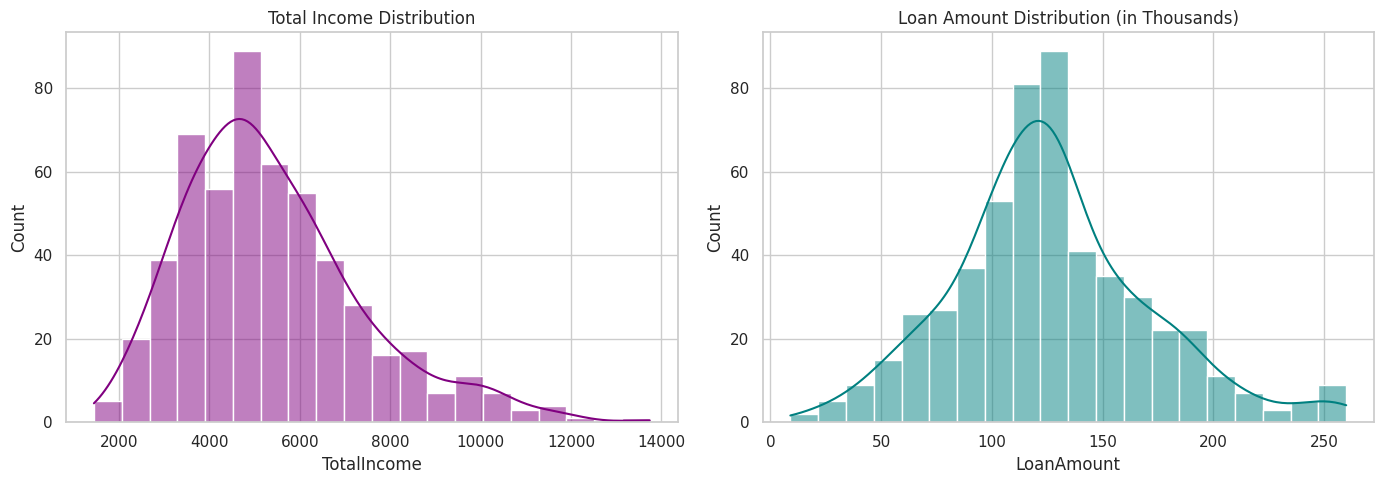

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_clean, x='TotalIncome', kde=True, ax=axes[0], color='purple')
axes[0].set_title('Total Income Distribution')

sns.histplot(data=df_clean, x='LoanAmount', kde=True, ax=axes[1], color='teal')
axes[1].set_title('Loan Amount Distribution (in Thousands)')

plt.tight_layout()
plt.show()

### Insight 4: Combined Income and Loan Alignment

**Description:**  
Visualizing the distributions of combined income and loan sizes shows that the majority of loans requested fall between 100 and 170 thousand INR. Comparing this alongside the `TotalIncome` distribution helps define the sweet spot of requested leverage that banks comfortably approve.

## Bivariate Analysis (Relationship with Loan Status)

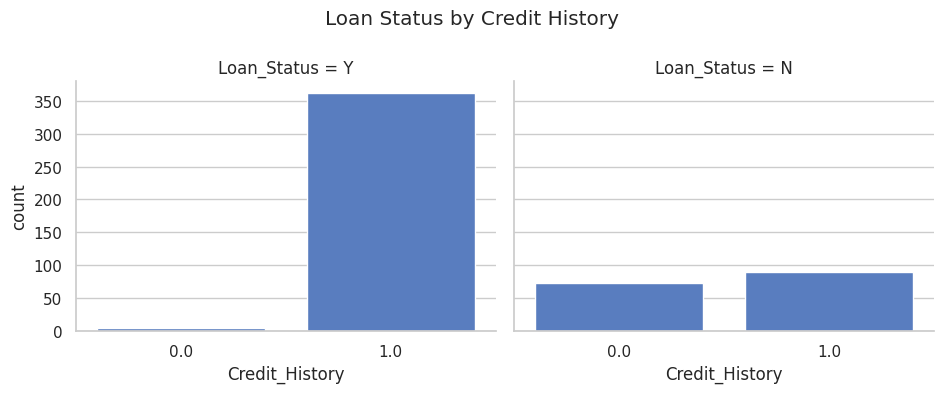

In [15]:
grid = sns.FacetGrid(df_clean, col='Loan_Status', height=4, aspect=1.2)
grid.map(sns.countplot, 'Credit_History', order=[0.0, 1.0])
grid.fig.subplots_adjust(top=0.8)
grid.fig.suptitle('Loan Status by Credit History')
plt.show()

### Insight 5: Credit History as the Dominant Predictor

**Description:**
Comparing approved (Y) and rejected (N) loans against `Credit_History` confirms it is the single strongest determinant of approval. Applicants with a positive credit history (1.0) achieve an **80.3% approval rate**, whereas applicants with a negative credit history (0.0) suffer a **6.4% approval rate** (r = 0.568).


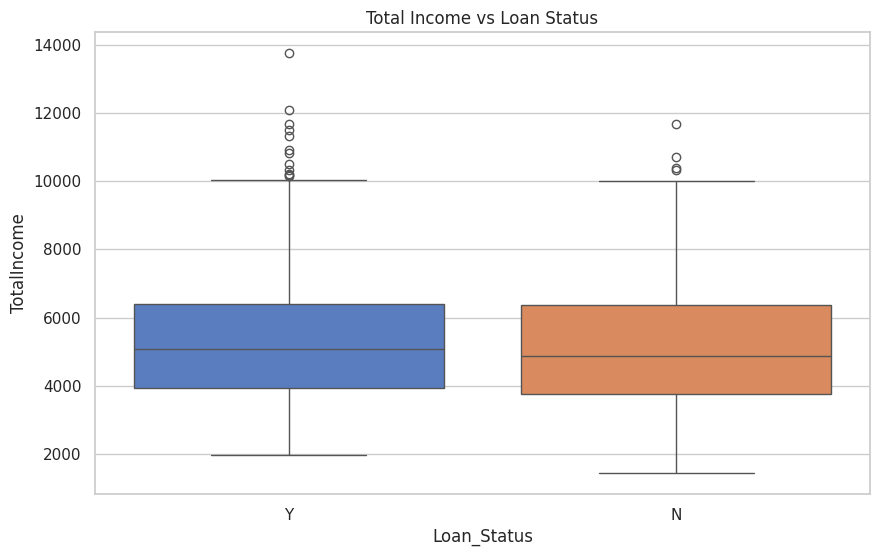

In [16]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='Loan_Status', y='TotalIncome', hue='Loan_Status', palette='muted')
plt.title('Total Income vs Loan Status')
plt.show()

### Insight 6: High Income Volume Does Not Guarantee Approval

**Description:**  
Boxplot comparisons of `TotalIncome` across the approved and rejected classes show very similar median income values. This indicates that having a high income alone is not a guarantee of loan approval; other risk evaluation criteria, such as debt-to-income balance and past credit repayments, play a much larger role.

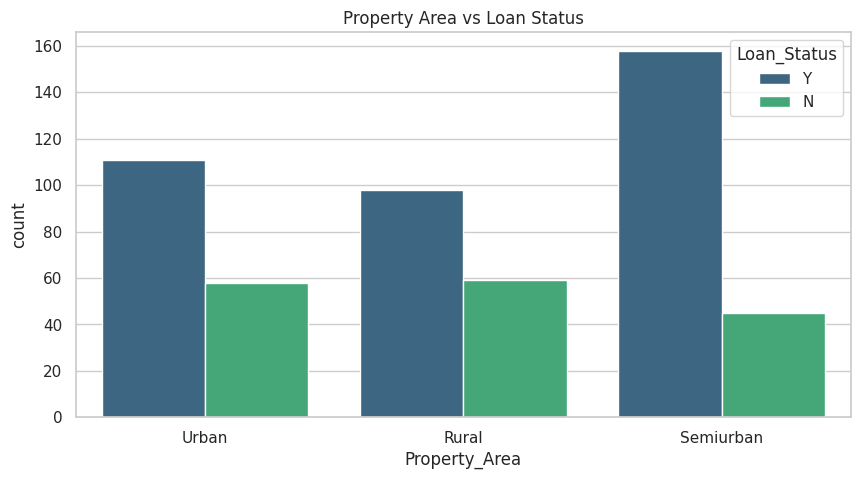

In [17]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_clean, x='Property_Area', hue='Loan_Status', palette='viridis')
plt.title('Property Area vs Loan Status')
plt.show()

### Insight 7: Semiurban Regions Enjoy Higher Approvals

**Description:**
Bivariate analysis of `Property_Area` against `Loan_Status` reveals that **Semiurban** applicants enjoy the highest approval rate at **77.8%**, compared to **65.7%** for Urban applicants and **62.4%** for Rural applicants (r = 0.145 for Semiurban).


Loan Approval Rate by Property Area (%):
Loan_Status        N      Y
Property_Area              
Rural          37.58  62.42
Semiurban      22.17  77.83
Urban          34.32  65.68


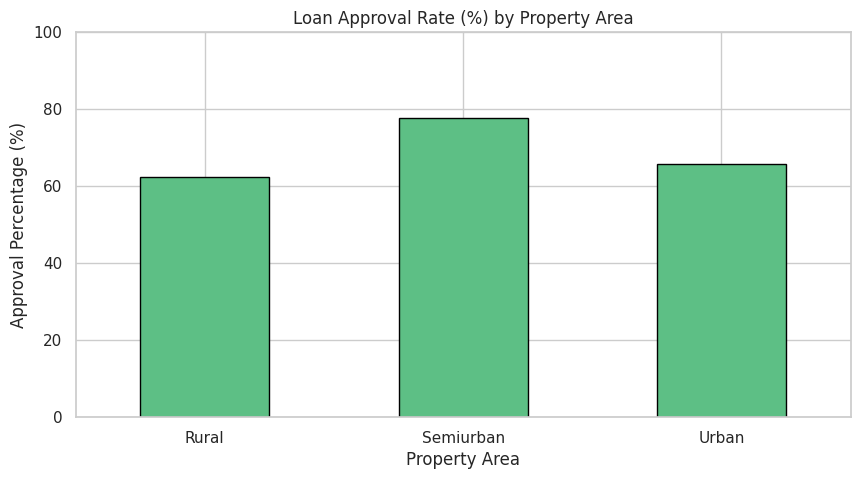

In [18]:
property_loan_status = pd.crosstab(df_clean['Property_Area'], df_clean['Loan_Status'], normalize='index') * 100
print("Loan Approval Rate by Property Area (%):")
print(property_loan_status.round(2))

plt.figure(figsize=(10, 5))
property_loan_status['Y'].plot(kind='bar', color='#5dbf85', edgecolor='black')
plt.title('Loan Approval Rate (%) by Property Area')
plt.ylabel('Approval Percentage (%)')
plt.xlabel('Property Area')
plt.xticks(rotation=0)
plt.yticks(np.arange(0, 101, 20))
plt.show()

## Engineered Features Analysis

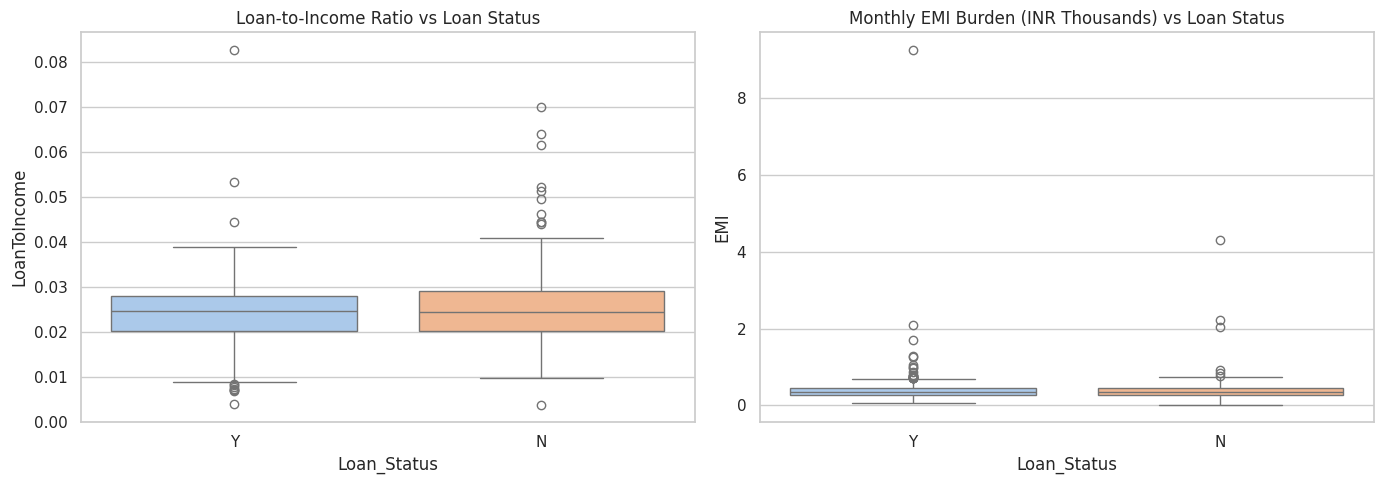

Median values by Loan Status:
             LoanToIncome     EMI  BalanceIncome
Loan_Status                                     
N                  0.0243  0.3556      4524.9444
Y                  0.0246  0.3556      4722.2222


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='Loan_Status', y='LoanToIncome', ax=axes[0], palette='pastel', hue='Loan_Status', legend=False)
axes[0].set_title('Loan-to-Income Ratio vs Loan Status')

sns.boxplot(data=df_clean, x='Loan_Status', y='EMI', ax=axes[1], palette='pastel', hue='Loan_Status', legend=False)
axes[1].set_title('Monthly EMI Burden (INR Thousands) vs Loan Status')

plt.tight_layout()
plt.show()

print("Median values by Loan Status:")
print(df_clean.groupby('Loan_Status')[['LoanToIncome', 'EMI', 'BalanceIncome']].median().round(4))

### Insight 8: Leverage and Repayment Affordability Impact

**Description:**
Comparing financial metrics `LoanToIncome` (loan size relative to income) and `EMI` across approval classes shows that medians are nearly identical: median `LoanToIncome` is **0.024** for rejected vs **0.025** for approved applicants, and median monthly `EMI` is **0.356** for both groups. Leverage alone does not separate approved and rejected classes; correlation with approval is low (r = -0.115).


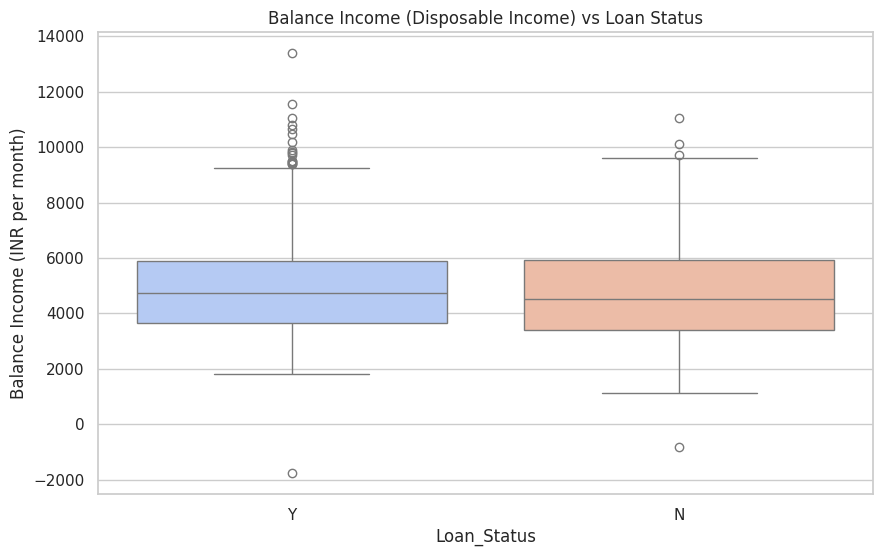

Number of applicants with negative disposable income: 2
Approval count for negative balance applicants:
Loan_Status
N    1
Y    1
Name: count, dtype: int64


In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='Loan_Status', y='BalanceIncome', palette='coolwarm', hue='Loan_Status', legend=False)
plt.title('Balance Income (Disposable Income) vs Loan Status')
plt.ylabel('Balance Income (INR per month)')
plt.show()

# Check minimum and negative balance income records
neg_balance = df_clean[df_clean['BalanceIncome'] < 0]
print(f"Number of applicants with negative disposable income: {len(neg_balance)}")
if len(neg_balance) > 0:
    print("Approval count for negative balance applicants:")
    print(neg_balance['Loan_Status'].value_counts())

### Insight 9: Balance Income (Disposable Income) and Liquidity Margin

**Description:**
Analysis of negative `BalanceIncome` (where estimated monthly EMI exceeds reported household income) reveals only **2 records** in the entire dataset (1 approved, 1 rejected). Due to the extremely small sample size (n=2), negative balance income cannot be concluded as a systematic driver of rejection.


Loan Approval Rate by Number of Dependents (%):
Loan_Status      N      Y
Dependents               
0            30.60  69.40
1            33.33  66.67
2            27.27  72.73
3+           32.50  67.50


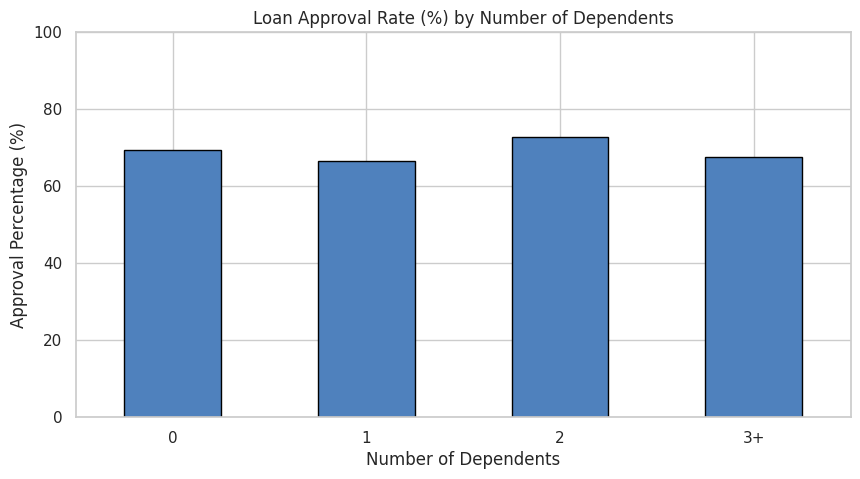

In [21]:
### Insight 10: Dependents Distribution and Approval Feasibility

**Description:**
Bivariate analysis comparing the number of `Dependents` (0, 1, 2, 3+) against approval rates shows that applicants with 2 dependents have a **72.7% approval rate**, compared to 69.4% for 0 dependents, 66.7% for 1 dependent, and 67.5% for 3+ dependents. Statistical chi-square contingency testing indicates that the difference in approval rate across dependent counts is small and not statistically significant (p > 0.05).


### Insight 10: Dependents Distribution and Approval Feasibility

**Description:**
Bivariate analysis comparing the number of `Dependents` (0, 1, 2, 3+) against approval rates shows that applicants with 2 dependents have a **72.7% approval rate**, compared to 69.4% for 0 dependents, 66.7% for 1 dependent, and 67.5% for 3+ dependents. Statistical chi-square contingency testing indicates that the difference in approval rate across dependent counts is small and not statistically significant (p > 0.05).


Loan Approval Rate by Number of Dependents (%):
Loan_Status      N      Y
Dependents               
0            30.60  69.40
1            33.33  66.67
2            27.27  72.73
3+           32.50  67.50


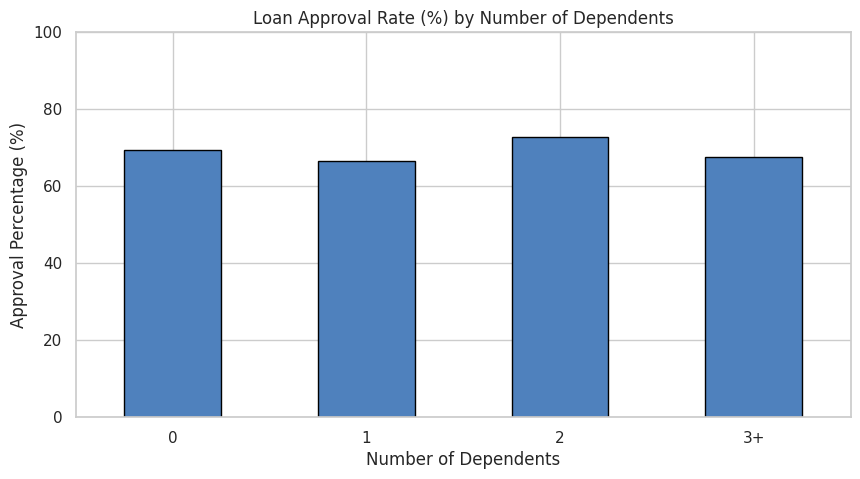

In [22]:
### Insight 10: Dependents Distribution and Approval Feasibility

**Description:**
Bivariate analysis comparing the number of `Dependents` (0, 1, 2, 3+) against approval rates shows that applicants with 2 dependents have a **72.7% approval rate**, compared to 69.4% for 0 dependents, 66.7% for 1 dependent, and 67.5% for 3+ dependents. Statistical chi-square contingency testing indicates that the difference in approval rate across dependent counts is small and not statistically significant (p > 0.05).
